<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter5/pinn_pendulum_gravity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Finding planet gravity from pendulum angle measurments.

 Starting Inverse PINN: Discovering Missing Gravity 


/tmp/ipykernel_736/174083111.py:149: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


Iteration  200 | Loss: 1157.65284 | Discovered Gravity: 1.2496 m/s^2
Iteration  400 | Loss: 935.55940 | Discovered Gravity: 2.8279 m/s^2
Iteration  600 | Loss: 771.26118 | Discovered Gravity: 4.6292 m/s^2
Iteration  800 | Loss: 713.01885 | Discovered Gravity: 6.7637 m/s^2
Iteration 1000 | Loss: 508.57821 | Discovered Gravity: 9.0938 m/s^2
Iteration 1200 | Loss: 408.02623 | Discovered Gravity: 10.1534 m/s^2
Iteration 1400 | Loss: 394.99010 | Discovered Gravity: 11.5307 m/s^2
Iteration 1600 | Loss: 360.10599 | Discovered Gravity: 13.3050 m/s^2
Iteration 1800 | Loss: 332.38124 | Discovered Gravity: 14.1678 m/s^2
Iteration 2000 | Loss: 301.00713 | Discovered Gravity: 16.2698 m/s^2
Iteration 2200 | Loss: 239.95410 | Discovered Gravity: 17.1642 m/s^2
Iteration 2400 | Loss: 212.72598 | Discovered Gravity: 17.4618 m/s^2
Iteration 2600 | Loss: 186.39464 | Discovered Gravity: 18.4831 m/s^2
Iteration 2800 | Loss: 39.41019 | Discovered Gravity: 19.6730 m/s^2
Iteration 3000 | Loss: 22.96682 | Disco

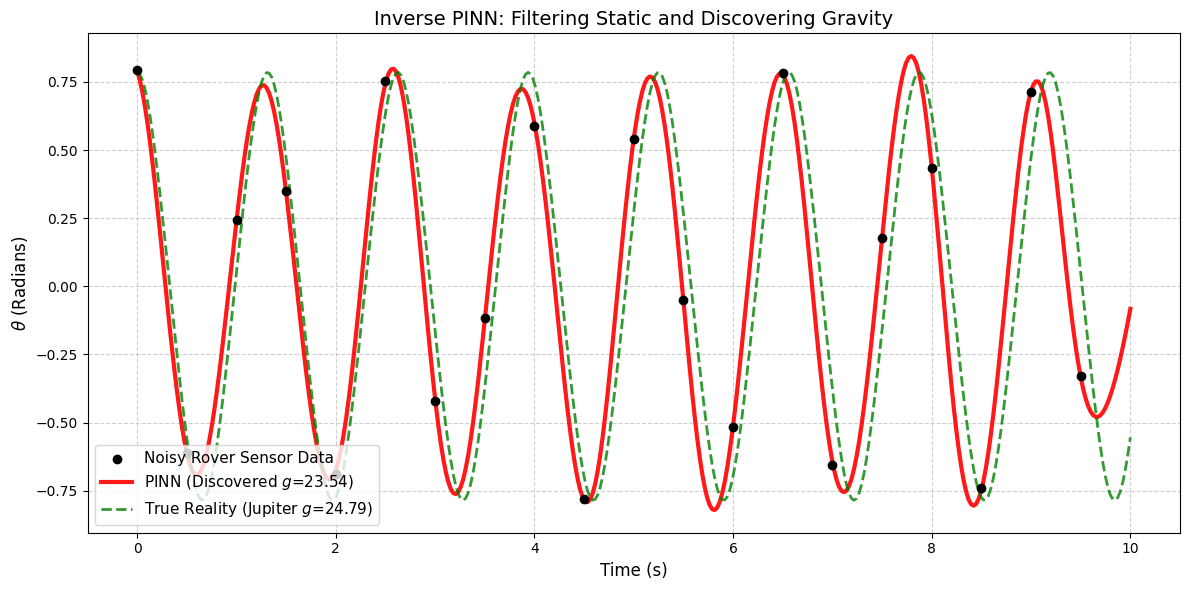

In [6]:
import jax
import jax.numpy as jnp
from jax import jit, value_and_grad, grad, vmap

# Force JAX to use 64-bit precision to match SciPy and prevent crashes
jax.config.update("jax_enable_x64", True)

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import scipy.special as sp
import time

# ==========================================
# 1. The Sparse, Noisy Rover Data
# ==========================================
# 20 noisy measurements over 10 seconds
t_data = np.array([0.00, 0.50, 1.00, 1.50, 2.00, 2.50, 3.00, 3.50, 4.00, 4.50,
                   5.00, 5.50, 6.00, 6.50, 7.00, 7.50, 8.00, 8.50, 9.00, 9.50]).reshape(-1, 1)

theta_data = np.array([0.792, -0.613, 0.244, 0.351, -0.687, 0.752, -0.421, -0.115, 0.589, -0.781,
                       0.541, -0.052, -0.518, 0.783, -0.655, 0.179, 0.433, -0.741, 0.712, -0.329]).reshape(-1, 1)

# Dense collocation points for the physics loss
t_domain = jnp.linspace(0, 10, 400).reshape(-1, 1)

# ==========================================
# 2. 2-Layer PINN Architecture (With an extra Trainable Parameter!)
# ==========================================
def unpack_weights(params, H):
    """
    Reconstructs the weight matrices from the flat 1D array.
    CRITICAL CHANGE: Notice we also unpack a single scalar value at the very end.
    This is our unknown Gravity parameter (lambda)!
    """
    idx = 0
    W1 = params[idx : idx+H].reshape(1, H); idx += H
    b1 = params[idx : idx+H].reshape(1, H); idx += H
    W2 = params[idx : idx+H*H].reshape(H, H); idx += H*H
    b2 = params[idx : idx+H].reshape(1, H); idx += H
    W3 = params[idx : idx+H].reshape(H, 1); idx += H
    b3 = params[idx : idx+1].reshape(1, 1); idx += 1

    # Extract the unknown physics parameter!
    lambda_param = params[idx]

    return W1, b1, W2, b2, W3, b3, lambda_param

def pack_weights(W1, b1, W2, b2, W3, b3, lambda_param):
    """Flattens weights and the unknown lambda into a 1D array."""
    return np.concatenate([
        W1.flatten(), b1.flatten(),
        W2.flatten(), b2.flatten(),
        W3.flatten(), b3.flatten(),
        lambda_param.flatten() # Appended to the very end
    ])

def predict_theta(params, t_scalar, H):
    # We unpack, but we intentionally ignore lambda here because the
    # network prediction function doesn't care about gravity.
    W1, b1, W2, b2, W3, b3, _ = unpack_weights(params, H)

    t_max = 10.0
    tau = t_scalar / t_max

    a1 = jnp.tanh(jnp.dot(tau, W1) + b1)
    a2 = jnp.tanh(jnp.dot(a1, W2) + b2)
    theta = jnp.dot(a2, W3) + b3
    return theta[0, 0]

# ==========================================
# 3. Universal AutoDiff Physics Builder
# ==========================================
# Ask JAX to build the derivatives
predict_velocity = grad(predict_theta, argnums=1)
predict_acceleration = grad(predict_velocity, argnums=1)

# Vectorize the scalar functions so they can run over arrays of time
vmap_theta = vmap(predict_theta, in_axes=(None, 0, None))
vmap_acceleration = vmap(predict_acceleration, in_axes=(None, 0, None))

def compute_loss(params, t_domain, t_data, theta_data, H):
    t_flat = t_domain.flatten()
    t_data_flat = t_data.flatten()

    # 1. Physics Loss (L_ODE)
    # This forces the curve to obey the physics equation, acting as a powerful
    # noise filter for the erratic data!
    _, _, _, _, _, _, lambda_param = unpack_weights(params, H)
    theta_pred_ode = vmap_theta(params, t_flat, H)
    acceleration_pred_ode = vmap_acceleration(params, t_flat, H)

    # The Physics Equation: acceleration + lambda * sin(theta) = 0
    # The network is forced to figure out what 'lambda' must be to make this true!
    residual = acceleration_pred_ode + lambda_param * jnp.sin(theta_pred_ode)
    loss_ode = jnp.mean(residual**2)

    # 2. Data Loss (L_Data)
    # This forces the curve to pass near the 20 noisy sensor points
    theta_pred_data = vmap_theta(params, t_data_flat, H)
    loss_data = jnp.mean((theta_pred_data - theta_data.flatten())**2)

    # THE GOLDILOCKS BALANCE:
    # 10,000x overfits the noise (gets ~21.4). 100x ignores the data and flatlines.
    # 5,000x is the sweet spot to guide it smoothly through the static without overfitting!
    return loss_ode + (5000.0 * loss_data)

loss_and_grad = jit(value_and_grad(compute_loss), static_argnums=(4,))

def scipy_objective(params, t_domain, t_data, theta_data, H):
    loss, grads = loss_and_grad(params, t_domain, t_data, theta_data, H)
    return float(loss), np.array(grads)

# ==========================================
# 4. Training Setup
# ==========================================
H = 32

np.random.seed(42)
# 15.0 scaling gives enough frequency to track Jupiter's gravity, but isn't overly chaotic.
W1 = np.random.randn(1, H) * 15.0
b1 = np.zeros((1, H))
W2 = np.random.randn(H, H) * np.sqrt(2.0 / (H + H))
b2 = np.zeros((1, H))
W3 = np.random.randn(H, 1) * np.sqrt(2.0 / (H + 1))
b3 = np.zeros((1, 1))

# Initialize our unknown Gravity guess!
# We start with 1.0 (Earth is ~9.8, so this is way off)
lambda_init = np.array([1.0])

current_weights = pack_weights(W1, b1, W2, b2, W3, b3, lambda_init)

progress = {'iterations': 0}

def monitor_progress(xk):
    progress['iterations'] += 1
    if progress['iterations'] % 200 == 0:
        current_loss = compute_loss(xk, t_domain, t_data, theta_data, H)
        # We can extract the current guess for lambda right from the end of the array!
        current_lambda = xk[-1]
        print(f"Iteration {progress['iterations']:4d} | Loss: {float(current_loss):.5f} | Discovered Gravity: {current_lambda:.4f} m/s^2")

print("==================================================")
print(" Starting Inverse PINN: Discovering Missing Gravity ")
print("==================================================")
start_time = time.time()

res = minimize(
    fun=scipy_objective,
    x0=current_weights,
    args=(t_domain, t_data, theta_data, H),
    method='L-BFGS-B',
    jac=True,
    callback=monitor_progress,
    options={'maxiter': 5000, 'maxfun': 50000, 'disp': False}
)

final_weights = res.x
_, _, _, _, _, _, final_lambda = unpack_weights(final_weights, H)

elapsed = time.time() - start_time
print(f"\nTraining Complete in {elapsed:.2f}s!")
print(f"Final Loss: {res.fun:.6f}")
print(f">>> FINAL DISCOVERED GRAVITY: {final_lambda:.4f} m/s^2 <<<")
print(f"(True Jupiter Gravity is ~24.79 m/s^2)")

# ==========================================
# 5. Evaluation and Plotting
# ==========================================
t_plot = np.array(t_domain).flatten()
theta_pred = np.array(vmap_theta(final_weights, t_plot, H))

# Calculate Exact Noiseless Solution based on true Jupiter gravity
true_lambda = 24.79
true_omega = np.sqrt(true_lambda)
theta_0 = 0.785 # 45 degrees initial push
k = np.sin(theta_0 / 2)
m = k**2

# Scale time by the true frequency for the exact solution
t_scaled = true_omega * t_plot
sn, cn, dn, ph = sp.ellipj(t_scaled, m)
exact_solution = 2 * np.arcsin(k * cn)

plt.figure(figsize=(12, 6))

# Plot the Noisy Sensor Data
plt.scatter(t_data, theta_data, color='black', label='Noisy Rover Sensor Data', zorder=5)

# Plot the PINN's Continuous Prediction
plt.plot(t_plot, theta_pred, 'r-', linewidth=3, alpha=0.9, label=f'PINN (Discovered $g$={final_lambda:.2f})')

# Plot the True Underlying Reality
plt.plot(t_plot, exact_solution, 'g--', linewidth=2, alpha=0.8, label=f'True Reality (Jupiter $g$={true_lambda})')

plt.title("Inverse PINN: Filtering Static and Discovering Gravity", fontsize=14)
plt.xlabel("Time (s)", fontsize=12)
plt.ylabel("$\\theta$ (Radians)", fontsize=12)
plt.legend(loc='lower left', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()